<a href="https://colab.research.google.com/github/Neha-984055/Deep-Learning/blob/main/dl_session_1_skill.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 14.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
import cv2
import time
import torch
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files

print("Libraries imported successfully!")
print("GPU Available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully!
GPU Available: True


Saving AI Traffic Detection on Hyderabad Street.png to AI Traffic Detection on Hyderabad Street.png
Image uploaded: AI Traffic Detection on Hyderabad Street.png


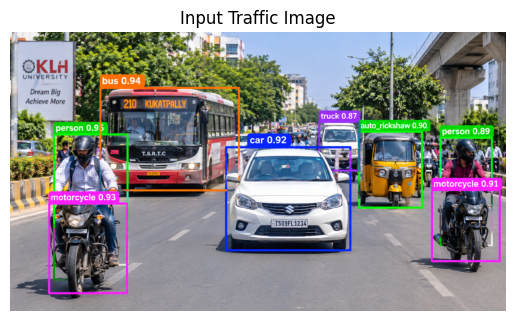

In [ ]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded:", image_path)

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.title("Input Traffic Image")
plt.axis("off")
plt.show()

In [ ]:
# Load pre-trained YOLO model
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [ ]:
# Start time
start_time = time.time()

# Detect objects
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

# End time
end_time = time.time()

print("Object detection completed!")
print("Processing time:", round(end_time-start_time, 3), "seconds")


image 1/1 /content/AI Traffic Detection on Hyderabad Street.png: 384x640 6 persons, 2 cars, 1 motorcycle, 1 bus, 2 trucks, 7.2ms
Speed: 81.5ms preprocess, 7.2ms inference, 27.4ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict
Object detection completed!
Processing time: 9.938 seconds


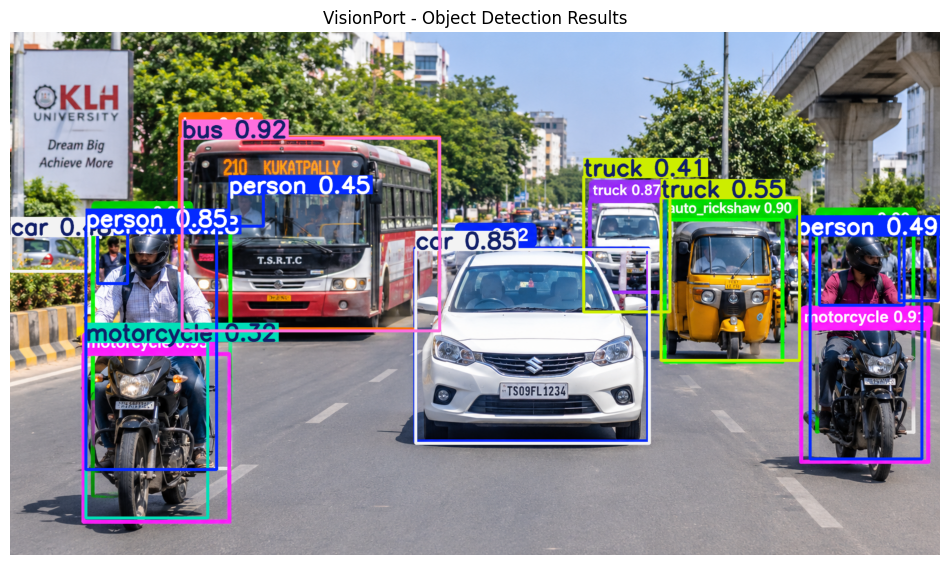

In [ ]:
# Get detected image
result_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.title("VisionPort - Object Detection Results")
plt.axis("off")
plt.show()

In [ ]:
# Extract detected objects
detected_objects = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    confidence = float(box.conf[0])

    detected_objects.append(class_name)

    print(
        "Object:", class_name,
        "| Confidence:", round(confidence, 2)
    )

print("\nTotal objects detected:", len(detected_objects))

Object: bus | Confidence: 0.92
Object: person | Confidence: 0.85
Object: car | Confidence: 0.85
Object: truck | Confidence: 0.55
Object: person | Confidence: 0.49
Object: car | Confidence: 0.48
Object: person | Confidence: 0.45
Object: person | Confidence: 0.44
Object: person | Confidence: 0.41
Object: truck | Confidence: 0.41
Object: motorcycle | Confidence: 0.32
Object: person | Confidence: 0.28

Total objects detected: 12


In [ ]:
# Save model weights
model.save("visionport_checkpoint.pt")

print("Model checkpoint saved successfully!")

Model checkpoint saved successfully!


In [ ]:
# Load model with FP16 precision
optimized_model = YOLO("yolov8n.pt")

start = time.time()

optimized_results = optimized_model.predict(
    source=image_path,
    conf=0.25,
    half=torch.cuda.is_available()
)

end = time.time()

print("Optimised inference completed!")
print("Inference time:", round(end-start, 3), "seconds")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

image 1/1 /content/AI Traffic Detection on Hyderabad Street.png: 384x640 6 persons, 2 cars, 1 motorcycle, 1 bus, 2 trucks, 7.3ms
Speed: 1.9ms preprocess, 7.3ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)
Optimised inference completed!
Inference time: 0.406 seconds


In [ ]:
print("VISIONPORT PERFORMANCE REPORT")

print("--------------------------------")

print("Total detected objects:", len(results[0].boxes))

print("Inference time:",
      round(end_time-start_time, 3), "seconds")

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("--------------------------------")
print("Monitoring completed!")

VISIONPORT PERFORMANCE REPORT
--------------------------------
Total detected objects: 12
Inference time: 9.938 seconds
GPU Available: True
GPU Name: Tesla T4
--------------------------------
Monitoring completed!


In [ ]:
# Save detected image
cv2.imwrite(
    "visionport_output.jpg",
    cv2.cvtColor(result_image, cv2.COLOR_RGB2BGR)
)

files.download("visionport_output.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>